# Multi-Purpose MLP for Joint Age, Gender and Ethnicity Prediction

This notebook trains **one fully connected neural network (MLP)** to perform three tasks at once from a 48 × 48 grayscale face image:

| Task | Type | Output |
|---|---|---|
| Gender | Binary classification | 2 classes (0 = male, 1 = female) |
| Ethnicity | Multi-class classification | 5 classes (0 = White, 1 = Black, 2 = Asian, 3 = Indian, 4 = Others) |
| Age | Regression | One continuous value (min–max scaled) |

The network has a shared **feature extractor** (five hidden layers) and three task-specific **output heads**. It is trained with a weighted sum of the three task losses, which is a simple form of multi-task learning.

This was Assignment 1 of the **CS 878 Deep Learning** course (Fall 2023) at NUST SEECS. The assignment uses 7,000 of the roughly 23,700 face images in the provided CSV.

**Notebook outline:** Download Dataset → Load Dataset → Train, Validation and Test Split → Pre-processing → Model → Model Evaluation.

> **Note on running this notebook.** This is the original assignment notebook, kept as it was; only these explanatory cells have been added. It was run on Google Colab, and the execution counts show that cells weren't run strictly top to bottom (for example, the model class is defined before the cell that imports PyTorch). Read it as a documented record of the experiment.

# **Download Dataset**
download dataset from shared link and load libraries to runtime.

Downloads the assignment CSV (about 199 MB) from a shared Google Drive link with `gdown`.

> Note: `gdown` saves the file to `/content/DL_assignment1_dataset.csv`, but the loading cell below reads it from `/content/drive/MyDrive/Dl_Assignment/DL_assignment1_dataset.csv`, and Google Drive isn't mounted anywhere in this notebook. Point the path in the loading cell at wherever the CSV is stored.

In [ ]:
!gdown https://drive.google.com/file/d/1_KRWsOhQNf6BZcdu4pg2JVy-lHo7_Cno/view?usp=sharing --fuzzy

Downloading...
From: https://drive.google.com/uc?id=1_KRWsOhQNf6BZcdu4pg2JVy-lHo7_Cno
To: /content/DL_assignment1_dataset.csv
100% 199M/199M [00:01<00:00, 157MB/s]


### Imports

Loads pandas for tabular data handling, NumPy for array operations and Matplotlib for plotting. PyTorch is imported later, just before the training data is converted to tensors.

In [1]:
import pandas
import copy
import numpy as np
import matplotlib.pyplot as plt

# **Load Dataset**

Reads the CSV into a DataFrame with 23,705 rows and four columns:

- **`age`**: an integer from 0 to 116 (the regression target).
- **`ethnicity`**: an integer from 0 to 4.
- **`gender`**: 0 or 1.
- **`pixels`**: a 48 × 48 grayscale image flattened into a string of 2,304 space-separated intensity values.

In [2]:
# Lets use pandas to load our data
df = pandas.read_csv("/content/drive/MyDrive/Dl_Assignment/DL_assignment1_dataset.csv")
df

,age,ethnicity,gender,pixels
0,1,2,0,129 128 128 126 127 130 133 135 139 142 145 14...
1,1,2,0,164 74 111 168 169 171 175 182 184 188 193 199...
2,1,2,0,67 70 71 70 69 67 70 79 90 103 116 132 145 155...
3,1,2,0,193 197 198 200 199 200 202 203 204 205 208 21...
4,1,2,0,202 205 209 210 209 209 210 211 212 214 218 21...
...,...,...,...,...
23700,99,0,1,127 100 94 81 77 77 74 99 102 98 128 145 160 1...
23701,99,1,1,23 28 32 35 42 47 68 85 98 103 113 117 130 129...
23702,99,2,1,59 50 37 40 34 19 30 101 156 170 177 184 187 1...
23703,99,2,1,45 108 120 156 206 197 140 180 191 199 204 207...


We will select only 7000 images from the given dataset for our implementation

Draws a random subset of 7,000 images with a fixed seed (`random_state=42`), as the assignment requires. The seed makes the subset reproducible.

In [3]:
random_seed = 42
df_sampled = df.sample(n=7000, random_state=random_seed)
df_sampled.reset_index(drop=True, inplace=True)
df_sampled

,age,ethnicity,gender,pixels
0,49,1,1,31 32 28 27 34 38 37 40 47 51 52 57 72 93 118 ...
1,39,1,0,186 65 38 40 36 51 64 64 60 55 58 60 73 79 82 ...
2,8,4,0,20 23 35 34 45 65 69 72 79 92 106 115 134 148 ...
3,40,4,0,6 6 13 19 15 23 41 76 106 125 133 138 152 158 ...
4,27,0,0,31 31 29 51 98 136 162 175 176 178 178 179 184...
...,...,...,...,...
6995,49,3,0,128 130 131 131 132 134 134 140 72 43 102 77 1...
6996,28,1,1,28 22 19 23 16 22 19 31 64 81 88 96 108 120 13...
6997,32,3,1,221 229 227 200 166 115 146 198 186 184 178 15...
6998,41,0,0,58 61 76 58 83 71 74 90 71 112 77 91 111 135 1...


Convert pixels string to arrays

Each `pixels` entry is stored as text. This helper splits it and converts it to an integer NumPy array of length 2,304, which the next cell applies to every row.

In [4]:
def string_to_array(pixel_string):
    pixel_list = pixel_string.split()
    pixel_array = np.array([int(value) for value in pixel_list])
    return pixel_array

In [5]:
df_sampled['pixels'] = df_sampled['pixels'].apply(string_to_array)
df_sampled['pixels']

0       [31, 32, 28, 27, 34, 38, 37, 40, 47, 51, 52, 5...
1       [186, 65, 38, 40, 36, 51, 64, 64, 60, 55, 58, ...
2       [20, 23, 35, 34, 45, 65, 69, 72, 79, 92, 106, ...
3       [6, 6, 13, 19, 15, 23, 41, 76, 106, 125, 133, ...
4       [31, 31, 29, 51, 98, 136, 162, 175, 176, 178, ...
                              ...                        
6995    [128, 130, 131, 131, 132, 134, 134, 140, 72, 4...
6996    [28, 22, 19, 23, 16, 22, 19, 31, 64, 81, 88, 9...
6997    [221, 229, 227, 200, 166, 115, 146, 198, 186, ...
6998    [58, 61, 76, 58, 83, 71, 74, 90, 71, 112, 77, ...
6999    [19, 21, 20, 23, 33, 54, 90, 128, 149, 169, 17...
Name: pixels, Length: 7000, dtype: object

In [ ]:
df_sampled

,age,ethnicity,gender,pixels
0,49,1,1,"[31, 32, 28, 27, 34, 38, 37, 40, 47, 51, 52, 5..."
1,39,1,0,"[186, 65, 38, 40, 36, 51, 64, 64, 60, 55, 58, ..."
2,8,4,0,"[20, 23, 35, 34, 45, 65, 69, 72, 79, 92, 106, ..."
3,40,4,0,"[6, 6, 13, 19, 15, 23, 41, 76, 106, 125, 133, ..."
4,27,0,0,"[31, 31, 29, 51, 98, 136, 162, 175, 176, 178, ..."
...,...,...,...,...
6995,49,3,0,"[128, 130, 131, 131, 132, 134, 134, 140, 72, 4..."
6996,28,1,1,"[28, 22, 19, 23, 16, 22, 19, 31, 64, 81, 88, 9..."
6997,32,3,1,"[221, 229, 227, 200, 166, 115, 146, 198, 186, ..."
6998,41,0,0,"[58, 61, 76, 58, 83, 71, 74, 90, 71, 112, 77, ..."


Visualize an image from our dataset.

Reshapes one flattened vector back to 48 × 48 and shows it next to its labels. This is a sanity check that the pixel decoding is correct.

Age: 28
Ethnicity: 3
Gender: 0


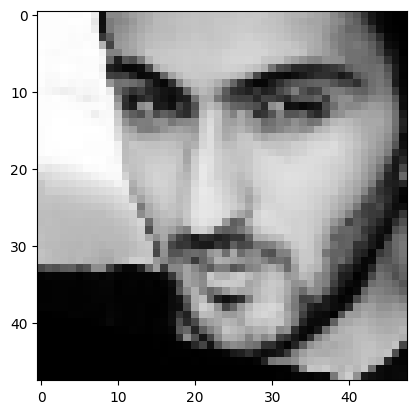

In [102]:
index = 30
first_image = df_sampled['pixels'][index]
image = first_image.reshape((48,48))
print("Age: "+str(df_sampled["age"][index])+"\nEthnicity: "+str(df_sampled["ethnicity"][index])+ "\nGender: "+str(df_sampled["gender"][index]))
plt.imshow(image,cmap="gray")

# **Train, Validation and Test Split**

Splitting the DataFrame into Training, Validation and Test sets with a ratio of 70%, 15% and 15% respectively.

Gender and ethnicity are one-hot encoded with `pandas.get_dummies`, which gives 2 gender columns and 5 ethnicity columns. The shuffled DataFrame is then split 70/15/15 into training (4,900 images), validation (1,050) and test (1,050) sets.

> Note: the shuffle (`df.sample(frac=1)`) has no `random_state`, so the split changes every time the notebook runs.

In [39]:
df = pandas.get_dummies(df_sampled, columns=['gender', 'ethnicity'], prefix=['gender', 'ethnicity'])


In [40]:
train, validate, test = np.split(df.sample(frac=1), [int(.7*len(df)), int(.85*len(df))])

In [41]:
print(f'Train shape: {train.shape} \nValid shape: {validate.shape} \nTest shape: {test.shape}')

Train shape: (4900, 9) 
Valid shape: (1050, 9) 
Test shape: (1050, 9)


In [42]:
train

,age,pixels,gender_0,gender_1,ethnicity_0,ethnicity_1,ethnicity_2,ethnicity_3,ethnicity_4
2685,8,"[46, 42, 37, 44, 42, 55, 37, 45, 80, 78, 101, ...",1,0,1,0,0,0,0
5150,20,"[182, 155, 131, 104, 82, 86, 71, 101, 90, 86, ...",1,0,1,0,0,0,0
4214,48,"[76, 109, 120, 131, 133, 142, 148, 151, 147, 1...",1,0,1,0,0,0,0
2504,60,"[105, 103, 100, 94, 101, 115, 127, 141, 151, 1...",1,0,0,0,1,0,0
4474,26,"[41, 33, 25, 21, 23, 29, 28, 31, 31, 31, 29, 2...",1,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...
2988,80,"[216, 234, 192, 139, 120, 124, 110, 107, 160, ...",0,1,0,1,0,0,0
1013,24,"[77, 51, 36, 26, 55, 107, 146, 154, 159, 162, ...",0,1,1,0,0,0,0
5657,28,"[76, 103, 127, 143, 157, 164, 165, 171, 169, 1...",1,0,1,0,0,0,0
1589,20,"[2, 0, 1, 1, 1, 1, 0, 0, 2, 2, 5, 31, 68, 111,...",0,1,0,0,0,1,0


# **Pre-processing**

Creating numpy arrays for training set

For each split, the pixel lists are stacked into an `(N, 2304)` feature matrix and three target arrays are built: one-hot gender `(N, 2)`, one-hot ethnicity `(N, 5)` and age `(N, 1)`.

In [43]:


X_train = np.array(train["pixels"].tolist())
train_y_gender = np.array(train[['gender_0', 'gender_1']])
train_y_ethnicity = np.array(train[['ethnicity_0', 'ethnicity_1', 'ethnicity_2', 'ethnicity_3', 'ethnicity_4']])
train_y_age = np.array(train['age']).reshape(train.shape[0], 1)

Creating numpy arrays for Validation set

In [45]:
X_valid = np.array(validate["pixels"].tolist())
valid_y_gender = np.array(validate[['gender_0', 'gender_1']])
valid_y_ethnicity = np.array(validate[['ethnicity_0', 'ethnicity_1', 'ethnicity_2', 'ethnicity_3', 'ethnicity_4']])
valid_y_age = np.array(validate['age']).reshape(validate.shape[0], 1)

Creating numpy arrays for Test set

In [46]:
X_test = np.array(test["pixels"].tolist())
test_y_gender = np.array(test[['gender_0', 'gender_1']])
test_y_ethnicity = np.array(test[['ethnicity_0', 'ethnicity_1', 'ethnicity_2', 'ethnicity_3', 'ethnicity_4']])
test_y_age = np.array(test['age']).reshape(test.shape[0], 1)

Scaling continous data to the range of 0-1.

Pixel intensities are divided by 255 to bring them into [0, 1]. Age is min–max scaled to [0, 1] so the regression loss is on a scale comparable to the two classification losses. The scaled arrays use capitalised names (`X_Train`, `Train_y_age`, and so on).

> Note: each split is scaled with its *own* minimum and maximum age, so the same scaled value can correspond to slightly different ages in different splits. The test MSE reported at the end is in these normalised units, not in years.

In [47]:
# Train scaling
X_Train = X_train/255.0
Train_y_age = (train_y_age - np.min(train_y_age))/(np.max(train_y_age)-np.min(train_y_age))

# Validation Scaling
X_Valid = X_valid/255.0
Valid_y_age = (valid_y_age - np.min(valid_y_age))/(np.max(valid_y_age)-np.min(valid_y_age))

# Test Scaling
X_Test = X_test/255.0
Test_y_age = (test_y_age - np.min(test_y_age))/(np.max(test_y_age)-np.min(test_y_age))



# Print Shape for all sets of data.

Checks the array shapes: 2,304 input features per image, and target widths of 2 (gender), 5 (ethnicity) and 1 (age).

In [48]:
print(f'X_Train shape: {X_train.shape} \nX_Valid shape: {X_Valid.shape} \nX_Test shape: {X_Test.shape}')

X_Train shape: (4900, 2304) 
X_Valid shape: (1050, 2304) 
X_Test shape: (1050, 2304)


In [49]:
print(f'train_y_gender shape: {train_y_gender.shape} \nvalid_y_gender shape: {valid_y_gender.shape} \ntest_y_gender shape: {test_y_gender.shape}')

train_y_gender shape: (4900, 2) 
valid_y_gender shape: (1050, 2) 
test_y_gender shape: (1050, 2)


In [50]:
print(f'train_y_ethnicity shape: {train_y_ethnicity.shape} \nvalid_y_ethnicity shape: {valid_y_ethnicity.shape} \ntest_y_ethnicity shape: {test_y_ethnicity.shape}')

train_y_ethnicity shape: (4900, 5) 
valid_y_ethnicity shape: (1050, 5) 
test_y_ethnicity shape: (1050, 5)


In [51]:
print(f'train_y_age shape: {Train_y_age.shape} \nvalid_y_age shape: {Valid_y_age.shape} \ntest_y_age shape: {Test_y_age.shape}')

train_y_age shape: (4900, 1) 
valid_y_age shape: (1050, 1) 
test_y_age shape: (1050, 1)


# Model

### Multi-task network

`MultiTaskNN` follows the design in the assignment brief:

- **Feature extractor:** five fully connected layers with ReLU activations. Their widths come from `hidden_size`; the run below uses 1024 → 1024 → 512 → 512 → 256. The last hidden layer gives a 256-dimensional representation of the image that all three tasks share.
- **Output heads:** three linear layers on top of that representation. The gender head has 2 units with softmax, the ethnicity head has 5 units with softmax, and the age head has 1 linear unit.
- **`calculate_accuracy`:** computes the argmax accuracy of both classification heads.
- **`predict`:** returns the three head outputs for new inputs.
- **`train`:** trains on the **full batch**, so each epoch is one forward and backward pass over the entire training set with Adam. The total loss is a weighted sum, `0.6 × gender CE + 0.7 × ethnicity CE + 0.3 × age MSE`, which is the weighted-loss option suggested in the brief. Training accuracy and the age loss are printed every 10 epochs.

> Notes:
> - This cell uses `torch`, `nn` and `optim`, which are imported in the next cell. The execution counts show the import cell ran first.
> - Both classification heads apply softmax, and their outputs are passed to `nn.CrossEntropyLoss`, which applies log-softmax internally. Applying softmax twice flattens the gradients and can slow learning. `BCELoss` is defined but not used.
> - The custom `train` method overrides `nn.Module.train` and refers to the global variable `model` instead of `self`.
> - The validation split isn't used during training.

In [114]:

class MultiTaskNN(nn.Module):
    def __init__(self, input_size, binary_output_size, category_output_size, regression_output_size, hidden_size=None):
        super(MultiTaskNN, self).__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # layers for the hidden
        self.hidden_layer1 = nn.Linear(input_size, hidden_size[0])
        self.hidden_layer2 = nn.Linear(hidden_size[0], hidden_size[1])
        self.hidden_layer3 = nn.Linear(hidden_size[1], hidden_size[2])
        self.hidden_layer4 = nn.Linear(hidden_size[2], hidden_size[3])
        self.hidden_layer5 = nn.Linear(hidden_size[3], hidden_size[4])

        # Output heads
        self.binary_layer = nn.Linear(hidden_size[4], binary_output_size)
        self.category_layer = nn.Linear(hidden_size[4], category_output_size)
        self.regression_layer = nn.Linear(hidden_size[4], regression_output_size)

    def forward(self, x):
        # 5 Hidden layers
        a_hidden = torch.relu(self.hidden_layer1(x))
        b_hidden = torch.relu(self.hidden_layer2(a_hidden))
        c_hidden = torch.relu(self.hidden_layer3(b_hidden))
        d_hidden = torch.relu(self.hidden_layer4(c_hidden))
        e_hidden = torch.relu(self.hidden_layer5(d_hidden))

        # Binary classification for one_hot encoded data
        a_binary = torch.softmax(self.binary_layer(e_hidden), dim=1)

        # Categorical classification
        a_category = torch.softmax(self.category_layer(e_hidden), dim=1)

        # Regression
        a_regression = self.regression_layer(e_hidden)

        return a_binary, a_category, a_regression, e_hidden

    def calculate_accuracy(self, a_binary, y_binary, a_category, y_category):
        binary_predictions = torch.argmax(a_binary, dim=1)
        category_predictions = torch.argmax(a_category, dim=1)
        y_binar =  torch.argmax(y_binary, dim=1)
        y_cat =  torch.argmax(y_category, dim=1)

        binary_accuracy = (binary_predictions == y_binar).float().mean().item()
        category_accuracy = (category_predictions == y_cat).float().mean().item()

        return binary_accuracy, category_accuracy

    def predict(self, x):
        a_binary, a_category, a_regression, _ = self.forward(x)
        return a_binary, a_category, a_regression


    def train(self, X, y_binary, y_category, y_regression, num_epochs=200, lr=0.001):
        # Define loss functions
        binary_criterion = nn.BCELoss()
        categorical_criterion = nn.CrossEntropyLoss()
        regression_criterion = nn.MSELoss()

        # Define the optimizer
        optimizer = optim.Adam(model.parameters(), lr=lr)

        for epoch in range(num_epochs):
            # Forward pass
            a_binary, a_category, a_regression, c_hidden = model(X)

            # cross-entropy loss, one hot encoded labels were passed
            binary_loss = categorical_criterion(a_binary, y_binary)

            # Categorical classification loss (cross-entropy)
            category_loss = categorical_criterion(a_category, y_category)

            # Regression loss (mse)
            regression_loss = regression_criterion(a_regression, y_regression)

            # Total weighted loss
            total_loss = 0.6*binary_loss + 0.7*category_loss + 0.3*regression_loss

            # Backpropagation
            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()

            if epoch % 10 == 0:
                binary_accuracy, category_accuracy = model.calculate_accuracy(a_binary, y_binary, a_category, y_category)
                binary_accuracy = round(binary_accuracy, 2)
                category_accuracy = round(category_accuracy, 2)
                print(f"Binary Accuracy: {binary_accuracy * 100}%, Category Accuracy: {category_accuracy * 100}%")
                print(f"Epoch {epoch},  Regression Loss: {regression_loss.item()}")



### Convert training data to tensors

Imports PyTorch and converts the scaled training features and the three target arrays to `float32` tensors. The whole training set is kept in one tensor because training is full-batch.

In [53]:
import torch
import torch.nn as nn
import torch.optim as optim


num_samples = X_Train.shape[0]
input_size = X_Train.shape[1]

# Convert data to PyTorch tensors
X = torch.from_numpy(X_Train).float()
binary_targets = torch.from_numpy(train_y_gender).float()
categorical_targets = torch.from_numpy(train_y_ethnicity).float()
regression_targets = torch.from_numpy(Train_y_age).float()


### Train the model

Builds the network with hidden sizes `[1024, 1024, 512, 512, 256]` and trains it for 120 epochs with Adam at a learning rate of 1e-4.

**Recorded training log** (on the training set, printed every 10 epochs):

- Gender accuracy rises from 47 % at epoch 0 to 77 % at epoch 110.
- Ethnicity accuracy stays at 43 % throughout.
- The normalised age MSE falls from 0.136 to 0.030.

In [115]:
# Create and initialize the model
binary_output_size = train_y_gender.shape[1]
category_output_size = train_y_ethnicity.shape[1]
regression_output_size = train_y_age.shape[1]

model = MultiTaskNN(input_size, binary_output_size, category_output_size, regression_output_size, hidden_size=[1024, 1024,512, 512, 256])

num_epochs = 120
learning_rate = 0.0001

# Train the model

model.train(X, binary_targets, categorical_targets, regression_targets, num_epochs, learning_rate)

Binary Accuracy: 47.0%, Category Accuracy: 43.0%
Epoch 0,  Regression Loss: 0.13583244383335114
Binary Accuracy: 56.99999999999999%, Category Accuracy: 43.0%
Epoch 10,  Regression Loss: 0.051325272768735886
Binary Accuracy: 53.0%, Category Accuracy: 43.0%
Epoch 20,  Regression Loss: 0.037664759904146194
Binary Accuracy: 53.0%, Category Accuracy: 43.0%
Epoch 30,  Regression Loss: 0.03654750809073448
Binary Accuracy: 63.0%, Category Accuracy: 43.0%
Epoch 40,  Regression Loss: 0.03552890196442604
Binary Accuracy: 63.0%, Category Accuracy: 43.0%
Epoch 50,  Regression Loss: 0.035490065813064575
Binary Accuracy: 67.0%, Category Accuracy: 43.0%
Epoch 60,  Regression Loss: 0.03549102693796158
Binary Accuracy: 68.0%, Category Accuracy: 43.0%
Epoch 70,  Regression Loss: 0.03413838893175125
Binary Accuracy: 70.0%, Category Accuracy: 43.0%
Epoch 80,  Regression Loss: 0.033638592809438705
Binary Accuracy: 73.0%, Category Accuracy: 43.0%
Epoch 90,  Regression Loss: 0.032757412642240524
Binary Accura

# Model Evaluation

Prediction on Test Set

Runs the trained network on the 1,050 test images. It returns gender probabilities, ethnicity probabilities and normalised age predictions.

In [116]:
gender, ethnicity, age = model.predict(torch.from_numpy(X_Test).float())

Converts the predicted probabilities and the one-hot test targets to class indices with `argmax`, so they can be compared.

In [119]:
gen_pred = torch.argmax(gender, dim=1)
eth_pre = torch.argmax(ethnicity, dim=1)
y_gen =  np.argmax(test_y_gender, axis=1)
y_eth =  np.argmax(test_y_ethnicity, axis=1)

Confusion Matrix for Gender

Plots the gender confusion matrix.

**Recorded result:** 788 of the 1,050 test images (429 male + 359 female) are on the diagonal, a test accuracy of about **75.0 %**.

> Note: `sklearn.metrics.confusion_matrix` puts the true labels on the rows (y-axis) and the predictions on the columns (x-axis). The axis titles in this plot are the wrong way round, so read the y-axis as *true* labels and the x-axis as *predicted* labels.

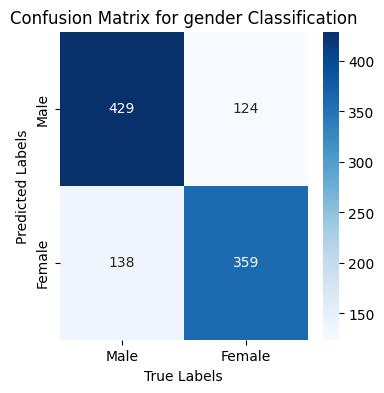

In [118]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Compute confusion matrix for binary classification
binary_cm = confusion_matrix(y_gen, gen_pred)
plt.figure(figsize=(4, 4))
sns.heatmap(binary_cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Male", "Female"], yticklabels=["Male", "Female"])
plt.xlabel("True Labels")
plt.ylabel("Predicted Labels")
plt.title("Confusion Matrix for gender Classification")
plt.show()

Confusion Matrix for Ethnicity

Plots the ethnicity confusion matrix.

**Recorded result:** the whole first column is filled and every other column is zero, so every test image is predicted as class 0 (White). Test accuracy is therefore 460 / 1,050 ≈ **43.8 %**, which is just the share of the majority class. The ethnicity head didn't learn to separate the classes, which matches the training accuracy that stayed flat at 43 %. The same axis-title swap applies: the rows are the true labels.

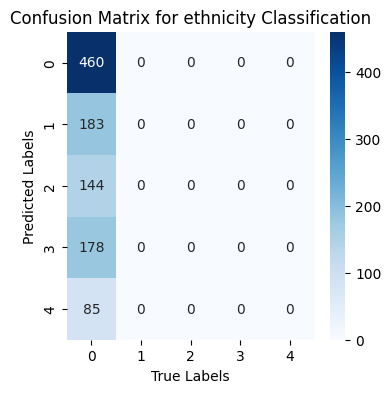

In [121]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Compute confusion matrix for categorical classification
cat_cm = confusion_matrix(y_eth, eth_pre)
plt.figure(figsize=(4, 4))
sns.heatmap(cat_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("True Labels")
plt.ylabel("Predicted Labels")
plt.title("Confusion Matrix for ethnicity Classification")
plt.show()

Mean Square Error for Age Test Set

Computes the mean squared error of the age predictions on the test set.

**Recorded result:** MSE = **0.0324** in normalised units, where age is min–max scaled to [0, 1] using the test set's own range. That is an RMSE of about 0.18 of the age range, not a value in years.

In [136]:
loss_reg = nn.MSELoss()
y_age = torch.from_numpy(Test_y_age).float()
regression_test_loss = loss_reg(age, y_age)
regression_test_loss.detach()

tensor(0.0324)

## Summary

- **Model:** a single MLP with a shared five-layer feature extractor and three task heads, trained full-batch with Adam (lr 1e-4, 120 epochs) on a weighted sum of the three task losses.
- **Gender:** about 75.0 % test accuracy, from the confusion matrix.
- **Ethnicity:** every test image is predicted as the majority class, giving 43.8 % test accuracy. The ethnicity head didn't learn a useful decision boundary.
- **Age:** test MSE of 0.0324 on min–max-normalised age.

Some items the assignment brief asks for aren't in this notebook: per-epoch validation, training and validation curves, and test losses for the classification tasks.

**Possible improvements (not tested here):** return raw logits from the classification heads so `CrossEntropyLoss` isn't applied after a softmax; train with mini-batches; use the validation split for model selection or early stopping; scale age with the training-set range for all splits; and tackle the ethnicity class imbalance, for example with class weights.